# Digital Image Processing — Week 5 · Task 3

**Grup: Nmertgules ve Iliya**

Renkli görüntüyü gri tonlu, tek kanallı görüntüye dönüştürme

Görüntü hem OpenCV'nin hazır fonksiyonu (`cv2.cvtColor`) hem de kendi yazdığımız fonksiyonla griye çevrilir. İki sonuçtaki eşleşen piksellerin **mutlak farklarının toplamı** hata değeri olarak raporlanır.

"Doğru" dönüşüm için üç noktaya dikkat edilir:

1. **Kanal sırası:** OpenCV görüntüyü **BGR** sırasıyla okur. Katsayılar R, G, B'ye göre tanımlı olduğundan kanalları doğru eşlemek gerekir.
2. **Ağırlıklı toplam:** İnsan gözü yeşile en duyarlı, maviye en az duyarlıdır. Bu yüzden basit ortalama değil, ITU-R BT.601 luma katsayıları kullanılır: `Y = 0.299·R + 0.587·G + 0.114·B`.
3. **Tek kanal, uint8:** Sonuç 0–255 aralığında yuvarlanmış tek kanallı bir görüntüdür.

In [1]:
from pathlib import Path
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Repodaki mevcut renkli fotoğrafı kullanıyoruz. Repo kökü çalışma klasöründen yukarı doğru aranır;
# böylece notebook hem repo kökünden hem de week5 içinden çalışır. Repo yoksa (ör. Colab) aynı
# fotoğraf GitHub'dan indirilir.
IMAGE_URL = 'https://raw.githubusercontent.com/Nmertgules/DEEP/main/week4/assets/rocket.jpg'

def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / 'week4' / 'assets' / 'rocket.jpg').is_file():
            return folder
    return None

ROOT = find_repo_root()
if ROOT is None:
    ROOT = Path('DEEP').resolve()
    (ROOT / 'week4' / 'assets').mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(IMAGE_URL, ROOT / 'week4' / 'assets' / 'rocket.jpg')
HERE = ROOT / 'week5'
IMAGE = ROOT / 'week4' / 'assets' / 'rocket.jpg'
OUT = HERE / 'results'
OUT.mkdir(parents=True, exist_ok=True)

bgr = cv2.imread(str(IMAGE), cv2.IMREAD_COLOR)
if bgr is None:
    raise FileNotFoundError(f'Görüntü okunamadı: {IMAGE}')
print(f'OpenCV {cv2.__version__} · Görüntü: {bgr.shape[1]} × {bgr.shape[0]}, {bgr.dtype}')

OpenCV 5.0.0 · Görüntü: 640 × 427, uint8


## Kendi fonksiyonlarımız

İki sürüm yazıyoruz:

- `bgr_to_gray_float`: formülü doğrudan kayan noktayla hesaplar ve en yakın tam sayıya yuvarlar.
- `bgr_to_gray`: OpenCV'nin 8 bit görüntüler için kullandığı **sabit noktalı (fixed-point)** hesabın aynısıdır. Katsayılar 2¹⁵ ile çarpılıp tam sayıya yuvarlanmıştır: `0.299·32768 ≈ 9798`, `0.587·32768 ≈ 19235`, `0.114·32768 ≈ 3735` (toplamları tam 32768). Sonuç `(B·3735 + G·19235 + R·9798 + 2¹⁴) >> 15` ile bulunur; `2¹⁴` eklemek, 15 bit sağa kaydırmadan önce en yakına yuvarlamayı sağlar.

Kayan nokta sürümü matematiksel olarak doğrudur, ancak OpenCV tam sayı yaklaşık katsayılarla çalıştığı için bazı piksellerde 1 gri seviyesi fark çıkar. Sabit noktalı sürüm OpenCV ile birebir aynıdır.

In [2]:
def bgr_to_gray_float(img):
    """BGR uint8 görüntüyü BT.601 ağırlıklarıyla griye çevir (kayan nokta + en yakına yuvarlama)."""
    if img.ndim != 3 or img.shape[2] != 3 or img.dtype != np.uint8:
        raise ValueError('3 kanallı uint8 BGR görüntü bekleniyor.')
    b, g, r = (img[..., i].astype(np.float64) for i in range(3))
    return np.clip(np.rint(0.299 * r + 0.587 * g + 0.114 * b), 0, 255).astype(np.uint8)


def bgr_to_gray(img):
    """BGR uint8 görüntüyü griye çevir; OpenCV'nin 15 bit sabit noktalı hesabıyla aynı."""
    if img.ndim != 3 or img.shape[2] != 3 or img.dtype != np.uint8:
        raise ValueError('3 kanallı uint8 BGR görüntü bekleniyor.')
    b, g, r = (img[..., i].astype(np.int32) for i in range(3))
    return ((b * 3735 + g * 19235 + r * 9798 + (1 << 14)) >> 15).astype(np.uint8)


def sad(a, b):
    """Eşleşen piksellerin mutlak farklarının toplamı (Sum of Absolute Differences)."""
    if a.shape != b.shape:
        raise ValueError(f'Boyutlar farklı: {a.shape} ve {b.shape}')
    return int(np.abs(a.astype(np.int64) - b.astype(np.int64)).sum())

## Dönüşüm ve hata değeri

In [3]:
gray_cv = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
gray_own = bgr_to_gray(bgr)
gray_float = bgr_to_gray_float(bgr)
assert gray_cv.ndim == gray_own.ndim == 2 and gray_own.dtype == np.uint8

error = sad(gray_cv, gray_own)
error_float = sad(gray_cv, gray_float)
print(f'Boyut: {gray_own.shape}, tek kanal, {gray_own.dtype}')
print(f'HATA DEĞERİ (OpenCV vs bgr_to_gray, sabit nokta) : {error}')
print(f'Kayan nokta sürümü için hata değeri             : {error_float} '
      f'({np.count_nonzero(gray_cv != gray_float)} pikselde 1 seviye fark)')

# Karşılaştırma için yanlış yapılan iki yaygın dönüşüm:
wrong_mean = np.rint(bgr.astype(np.float64).mean(axis=2)).astype(np.uint8)
wrong_order = bgr_to_gray(bgr[..., ::-1])   # BGR görüntüyü RGB sanmak
print(f'Yanlış: kanalların basit ortalaması              : {sad(gray_cv, wrong_mean)}')
print(f'Yanlış: BGR görüntüyü RGB sanmak                 : {sad(gray_cv, wrong_order)}')

Boyut: (427, 640), tek kanal, uint8
HATA DEĞERİ (OpenCV vs bgr_to_gray, sabit nokta) : 0
Kayan nokta sürümü için hata değeri             : 1 (1 pikselde 1 seviye fark)
Yanlış: kanalların basit ortalaması              : 1485367
Yanlış: BGR görüntüyü RGB sanmak                 : 2060383


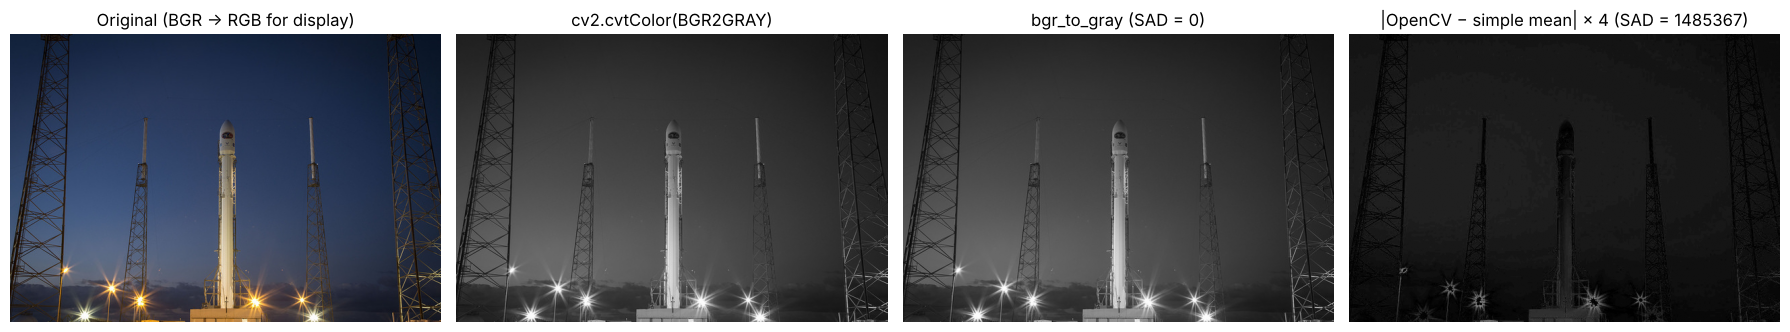

In [4]:
diff_mean = np.abs(gray_cv.astype(np.int16) - wrong_mean.astype(np.int16))
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
panels = [(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), 'Original (BGR → RGB for display)', None),
          (gray_cv, 'cv2.cvtColor(BGR2GRAY)', 'gray'),
          (gray_own, f'bgr_to_gray (SAD = {error})', 'gray'),
          (np.clip(diff_mean * 4, 0, 255), f'|OpenCV − simple mean| × 4 (SAD = {sad(gray_cv, wrong_mean)})', 'gray')]
for ax, (im, title, cmap) in zip(axes, panels):
    ax.imshow(im, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'task3_grayscale.png', dpi=110)
plt.show()

## Bütün renkler üzerinde kontrol

Tek bir fotoğraf her durumu kapsamayabilir. Bu yüzden 2²⁴ = 16.777.216 olası BGR rengin tamamı tek bir görüntüye yerleştirilir ve iki fonksiyon tekrar karşılaştırılır.

In [5]:
# 2^24 = 16.777.216 olası 8 bit BGR rengin tamamı, 4096 × 4096 boyutlu tek bir görüntüde.
codes = np.arange(1 << 24, dtype=np.uint32)
all_colors = np.dstack([codes & 255, (codes >> 8) & 255, (codes >> 16) & 255]).astype(np.uint8).reshape(4096, 4096, 3)

full_error = sad(cv2.cvtColor(all_colors, cv2.COLOR_BGR2GRAY), bgr_to_gray(all_colors))
full_error_float = sad(cv2.cvtColor(all_colors, cv2.COLOR_BGR2GRAY), bgr_to_gray_float(all_colors))
print(f'16.777.216 renk · sabit nokta hata değeri : {full_error}')
print(f'16.777.216 renk · kayan nokta hata değeri : {full_error_float}')
assert full_error == 0

16.777.216 renk · sabit nokta hata değeri : 0
16.777.216 renk · kayan nokta hata değeri : 22906


## Sonuç

- Kendi `bgr_to_gray` fonksiyonumuz OpenCV ile **birebir aynı** sonucu verir; hata değeri (mutlak farkların toplamı) fotoğrafta da bütün 16,7 milyon renkte de **0**'dır.
- Formülü kayan noktayla hesaplamak da doğrudur; yalnızca OpenCV'nin tam sayı katsayılarından kaynaklanan yuvarlama farkları yüzünden bazı piksellerde 1 seviye fark ve küçük bir hata değeri oluşur.
- Basit ortalama ya da yanlış kanal sırası çok daha büyük hatalar üretir. Bu, "doğru şekilde" dönüştürmenin ağırlıklı toplam ve doğru BGR eşlemesi anlamına geldiğini gösterir.
- Not: BT.601 katsayıları gamma uygulanmış (sRGB) değerlere doğrudan uygulanır, yani sonuç fiziksel parlaklık değil **luma** değeridir. OpenCV ve yaygın uygulamalar böyle çalışır.